# 02 — Feature Engineering : Détection d'anomalies fiscales
### Dataset : `data_FraudDetection_JAR2020.csv`

Ce notebook traite les problèmes identifiés lors de l'EDA, en s'appuyant sur la
méthodologie documentée par les auteurs du papier (fichiers `data_reader.m` et
`run_RUSBoost.m` du dépôt officiel) :

1. Split temporel avec gap de 2 ans (au lieu d'un split aléatoire)
2. Filtrage anti-fuite de données via `p_aaer` (fraude en série)
3. Choix des variables : 28 brutes seules vs brutes + 14 ratios
4. Transformation log sur les variables comptables très asymétriques
5. Gestion des NaN structurels sur les ratios dérivés
6. Sauvegarde des jeux de données transformés dans `data/processed/`

Les fonctions réutilisables (`temporal_split`, `signed_log1p`, ...) vivent
maintenant dans `src/` (`src/feature_engineering.py`, `src/preprocessing.py`)
plutôt que d'être redéfinies dans ce notebook — elles sont importées telles
quelles par `03_modeling_unsupervised.ipynb`, `04_modeling_supervised.ipynb`
et `05_modeling_supervised_v2.ipynb`, qui étaient auparavant chacun porteurs
d'une copie légèrement divergente de ce même code.

**Suite** : `03_modeling_unsupervised.ipynb`

## 0. Imports et chargement

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if (Path.cwd().parent / "src").exists() else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RAW_ACCOUNTING_VARS, RATIO_VARS, ID_VARS, DATA_RAW, DATA_PROCESSED, TEST_YEARS
from src.preprocessing import load_raw_data, add_log_features, add_missing_indicators_and_impute
from src.feature_engineering import temporal_split, split_summary, build_baseline_feature_lists
from src.viz import set_style, save_fig

pd.set_option("display.max_columns", 100)
set_style()

df = load_raw_data(DATA_RAW)
print("Shape :", df.shape)
df[ID_VARS].head()

Shape : (146045, 46)


,fyear,gvkey,p_aaer,misstate
0,1990,1009,NaN,0
1,1990,1011,NaN,0
2,1990,1017,NaN,0
3,1990,1021,NaN,0
4,1990,1028,NaN,0


## 1. Split temporel avec gap de 2 ans

Contrairement à un `train_test_split()` aléatoire, on reproduit la méthodologie
des auteurs : le modèle est entraîné sur les données allant jusqu'à
`year_test - 2`, avec un test sur `year_test` uniquement. Ce gap de 2 ans laisse
le temps aux AAER (Accounting and Auditing Enforcement Releases) d'être publiées
et aux labels de fraude de se stabiliser, ce qui évite d'entraîner un modèle sur
des années dont les fraudes ne sont pas encore toutes détectées.

`temporal_split()` (dans `src/feature_engineering.py`) applique aussi le
**filtrage anti-fuite** : toute observation du train dont le `p_aaer` apparaît
également dans le test (fraude en série, même affaire sur plusieurs années)
est retirée du train.

In [2]:
# Exemple sur une année de test (comme dans run_RUSBoost.m : 2003 à 2014)
df_train_example, df_test_example = temporal_split(df, year_test=2003)
print(split_summary(df, year_test=2003))

{'year_test': 2003, 'train_range': '1991-2001', 'train_obs': 67069, 'train_fraud': 402, 'n_removed_anti_leak': 97, 'test_obs': 5981, 'test_fraud': 69}


In [3]:
# Vérification : distribution de la cible sur cet exemple de split
print("Train - misstate:")
print(df_train_example["misstate"].value_counts(normalize=True).round(4) * 100)
print("\nTest - misstate:")
print(df_test_example["misstate"].value_counts(normalize=True).round(4) * 100)

Train - misstate:
misstate
0    99.4
1     0.6
Name: proportion, dtype: float64

Test - misstate:
misstate
0    98.85
1     1.15
Name: proportion, dtype: float64


### Validation glissante (rolling window)

Pour évaluer la robustesse du futur modèle dans le temps (et non sur une seule
année, potentiellement non représentative), on prépare l'ensemble des splits
de `year_test = 2003` à `2014`, comme dans `run_RUSBoost.m`.

In [4]:
summary_rows = [split_summary(df, year_test=year) for year in TEST_YEARS]
splits_summary = pd.DataFrame(summary_rows).set_index("year_test")
splits_summary

,train_range,train_obs,train_fraud,n_removed_anti_leak,test_obs,test_fraud
year_test,,,,,,
2003,1991-2001,67069,402,97,5981,69
2004,1991-2002,73124,467,109,5934,58
2005,1991-2003,79107,538,107,5863,45
2006,1991-2004,85105,660,43,5908,33
2007,1991-2005,90983,720,28,5868,30
2008,1991-2006,96896,758,23,5612,26
2009,1991-2007,102766,790,21,5367,31
2010,1991-2008,108369,807,30,5389,26
2011,1991-2009,113732,834,34,5404,21


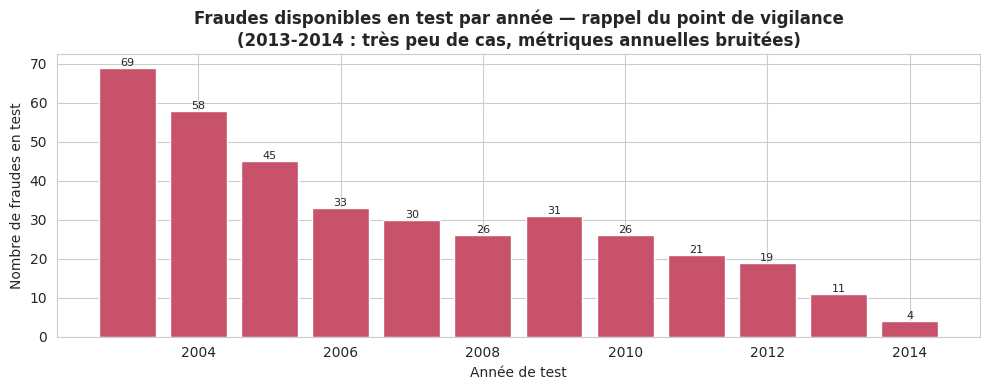

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(splits_summary.index, splits_summary["test_fraud"], color="#c9526b")
ax.set_xlabel("Année de test")
ax.set_ylabel("Nombre de fraudes en test")
ax.set_title("Fraudes disponibles en test par année — rappel du point de vigilance\n"
             "(2013-2014 : très peu de cas, métriques annuelles bruitées)")
for year, n in zip(splits_summary.index, splits_summary["test_fraud"]):
    ax.annotate(str(int(n)), (year, n), ha="center", va="bottom", fontsize=8)
fig.tight_layout()
save_fig(fig, "01_test_fraud_counts_by_year")
plt.show()

## 2. Choix des variables : bruts seuls vs bruts + ratios

Le code officiel (`data_reader.m`) n'utilise que les **28 variables comptables
brutes**, 100% complètes, pas les ratios dérivés (qui contiennent des NaN
structurels).

On garde ici les deux options disponibles, pour comparer plus tard en
modélisation :
- `FEATURES_BASELINE` : réplication fidèle du papier (28 brutes)
- `FEATURES_EXTENDED` : brutes + 14 ratios (valeur ajoutée, nécessite un
  traitement des NaN, cf. section 4)

In [6]:
feature_lists = build_baseline_feature_lists()
FEATURES_BASELINE = feature_lists["FEATURES_BASELINE"]
FEATURES_EXTENDED = feature_lists["FEATURES_EXTENDED"]

print(f"FEATURES_BASELINE : {len(FEATURES_BASELINE)} variables")
print(f"FEATURES_EXTENDED : {len(FEATURES_EXTENDED)} variables")

FEATURES_BASELINE : 28 variables
FEATURES_EXTENDED : 42 variables


## 3. Transformation log sur les variables comptables brutes

L'EDA a montré une asymétrie très forte sur les variables comptables brutes
(moyenne >> médiane, ex. `at` : moyenne=2374 vs médiane=105). On applique une
transformation `log1p` (log(1+x)), qui gère aussi les valeurs nulles.

Pour les variables pouvant être négatives (`ib`, `ni`, `re`, `ceq`...), on
utilise une transformation signée : `sign(x) * log1p(|x|)` (`signed_log1p`,
dans `src/preprocessing.py`), qui préserve le signe tout en réduisant
l'asymétrie des grandes valeurs.

In [7]:
df_transformed = add_log_features(df, RAW_ACCOUNTING_VARS)

log_cols = [c + "_log" for c in RAW_ACCOUNTING_VARS]
df_transformed[log_cols].describe().T[["mean", "50%", "std", "min", "max"]]

,mean,50%,std,min,max
act_log,3.958885,3.881584,2.293971,-0.226338,11.935772
ap_log,2.484423,2.009823,2.045836,0.000000,10.594232
at_log,4.794891,4.666698,2.507400,0.000000,12.924095
ceq_log,3.654928,3.877597,2.957874,-10.148823,12.558260
che_log,2.654274,2.339206,2.141804,-3.555348,11.358725
cogs_log,4.071676,3.996033,2.585635,-5.907118,12.984772
csho_log,3.290591,3.158701,1.389957,0.000000,11.513859
dlc_log,1.649981,0.859932,1.993091,-0.066724,11.232603
dltis_log,1.727237,0.061095,2.384063,-3.029505,12.148406
dltt_log,2.622170,1.700010,2.753877,0.000000,11.697536


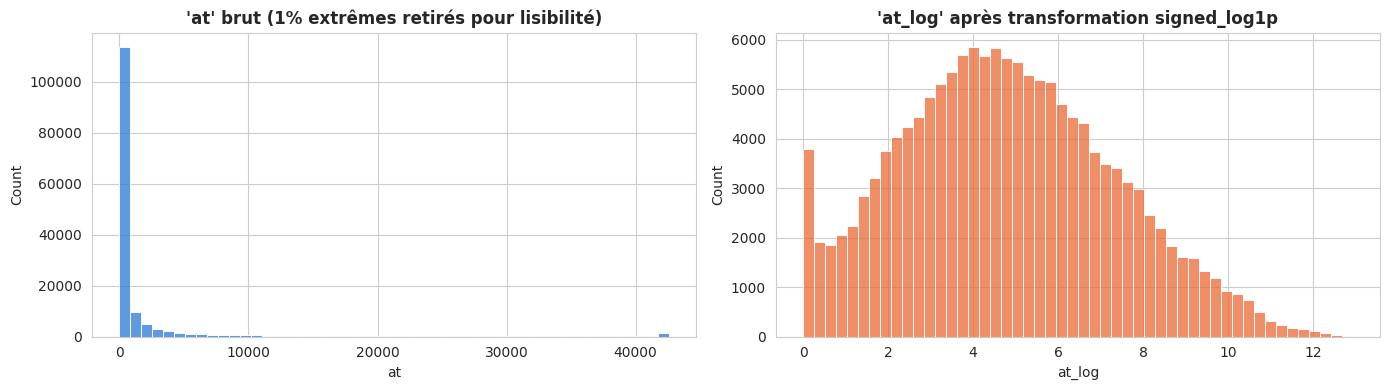

In [8]:
# Comparaison visuelle avant/après transformation sur une variable très asymétrique
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

import seaborn as sns
sns.histplot(df["at"].clip(upper=df["at"].quantile(0.99)), bins=50, ax=axes[0], color="#2a78d6")
axes[0].set_title("'at' brut (1% extrêmes retirés pour lisibilité)")

sns.histplot(df_transformed["at_log"], bins=50, ax=axes[1], color="#eb6834")
axes[1].set_title("'at_log' après transformation signed_log1p")

fig.tight_layout()
save_fig(fig, "02_log_transform_effect")
plt.show()

## 4. Gestion des NaN structurels sur les ratios

Les 14 ratios (`ch_*`, `dch_*`) sont des variations d'une année sur l'autre :
ils sont donc naturellement absents pour la première année d'observation de
chaque entreprise (`gvkey`). Ce n'est pas une erreur de saisie, c'est
structurel.

Stratégie retenue :
- Pour les modèles tolérants aux NaN (XGBoost) : on laisse tel quel
- Pour les modèles qui l'exigent (régression logistique, Isolation Forest,
  autoencoder) : on ajoute une version imputée par 0, avec un **indicateur
  binaire de valeur manquante** par variable (pratique courante pour ne pas
  perdre l'information "c'est la première année d'observation")

In [9]:
df_transformed = add_missing_indicators_and_impute(df_transformed, RATIO_VARS)

missing_indicator_cols = [c + "_was_missing" for c in RATIO_VARS]
df_transformed[missing_indicator_cols].sum().sort_values(ascending=False)

ch_cm_was_missing          17107
ch_cs_was_missing          15918
ch_roa_was_missing         12678
dpi_was_missing             9228
ch_fcf_was_missing          5407
ch_rsst_was_missing         4851
dch_wc_was_missing          4759
dch_rec_was_missing         4743
dch_inv_was_missing         4615
soft_assets_was_missing      592
reoa_was_missing             591
EBIT_was_missing             591
bm_was_missing                18
issue_was_missing              0
dtype: int64

## 5. Récapitulatif des jeux de variables finaux

In [10]:
feature_lists = build_baseline_feature_lists(missing_indicator_cols=missing_indicator_cols)
FEATURES_BASELINE_LOG = feature_lists["FEATURES_BASELINE_LOG"]
FEATURES_EXTENDED_LOG = feature_lists["FEATURES_EXTENDED_LOG"]

print(f"FEATURES_BASELINE_LOG : {len(FEATURES_BASELINE_LOG)} variables")
print(f"FEATURES_EXTENDED_LOG : {len(FEATURES_EXTENDED_LOG)} variables")

n_nan_extended = df_transformed[FEATURES_EXTENDED_LOG].isnull().sum().sum()
print("\nNaN restants (FEATURES_EXTENDED_LOG) :", n_nan_extended)
assert n_nan_extended == 0, "FEATURES_EXTENDED_LOG ne devrait plus contenir de NaN après imputation."

FEATURES_BASELINE_LOG : 28 variables
FEATURES_EXTENDED_LOG : 56 variables

NaN restants (FEATURES_EXTENDED_LOG) : 0


## 6. Sauvegarde

On sauvegarde :
- le dataset transformé complet (`data/processed/data_transformed.csv`)
- le résumé des splits temporels (années de test 2003-2014), pour être
  réutilisés à l'identique dans `03_modeling_unsupervised.ipynb` et
  `04_modeling_supervised.ipynb`, en appelant simplement `temporal_split()`
  (importé depuis `src.feature_engineering`) sur le dataset transformé

In [11]:
df_transformed.to_csv(DATA_PROCESSED, index=False)

print(f"Fichier sauvegardé : {DATA_PROCESSED}")
print("Shape :", df_transformed.shape)

Fichier sauvegardé : /tmp/work/project/data/processed/data_transformed.csv
Shape : (146045, 88)


In [12]:
# Contrôle de relecture : le fichier sauvegardé se recharge bien à l'identique
df_reloaded = pd.read_csv(DATA_PROCESSED)
assert df_reloaded.shape == df_transformed.shape, "Le fichier rechargé n'a pas la forme attendue."
df_reloaded[ID_VARS].head()

,fyear,gvkey,p_aaer,misstate
0,1990,1009,NaN,0
1,1990,1011,NaN,0
2,1990,1017,NaN,0
3,1990,1021,NaN,0
4,1990,1028,NaN,0


## Synthèse

- Split temporel avec gap de 2 ans + filtrage anti-fuite `p_aaer` : implémentés
  dans `src.feature_engineering.temporal_split()`, réutilisable pour toute
  année de test 2003-2014 sans redéfinition dans chaque notebook
- Deux jeux de variables disponibles : `FEATURES_BASELINE_LOG` (28, réplication
  du papier) et `FEATURES_EXTENDED_LOG` (56, avec ratios + indicateurs de NaN)
- Variables comptables brutes transformées en log signé pour réduire
  l'asymétrie
- Aucun NaN restant sur les jeux de variables retenus (vérifié par assertion,
  pas seulement affiché)
- Rappel visuel : les années 2013-2014 n'ont que 11 et 4 fraudes en test —
  toute lecture d'une métrique sur une seule année de cette fenêtre doit
  rester prudente (cf. graphique ci-dessus)

**Prochaine étape** : `03_modeling_unsupervised.ipynb` (Isolation Forest, LOF,
Autoencoder) sur `FEATURES_EXTENDED_LOG`, en utilisant `temporal_split()` pour
chaque année de test.